# Early Prediction of Vasopressor Initiation Using MIMIC-IV

**ML/DL tutorial | MIMIC-IV v3.1**  
**Author:** Shounak Ghosh (sg55893)

## Research question

**Can information recorded during the first six hours of an ICU stay predict new vasopressor initiation during the following 24 hours (hours 6–30)?** More specifically, do blood-pressure (BP) levels and short-term BP summaries improve prediction beyond admission information and laboratory results?

### Tutorial objectives

1. Construct an auditable cohort and future-treatment outcome from real MIMIC-IV electronic health record (EHR) tables.
2. Compare **three ML classifiers** (Decision Tree, Random Forest, Gradient Boosting) across **three nested feature sets** (baseline; baseline + BP levels; baseline + levels and temporal summaries).
3. Choose models and thresholds on validation data, then report an independent held-out test evaluation and uncertainty in the AUPRC gain.
4. Interpret feature importance and document the retrospective cohort's limitations.

**Clinical interpretation:** This predicts *documented treatment initiation*, not a diagnosis of shock or a recommendation to administer vasopressors.

### Data access and reproducibility

This notebook uses [MIMIC-IV v3.1](https://physionet.org/content/mimiciv/3.1/), which requires credentialed access. Data are queried through BigQuery from Google Colab; follow the [MIMIC BigQuery access instructions](https://mimic.mit.edu/docs/gettingstarted/cloud/link.html). Code cells contain their previously executed outputs; rerun from the beginning with your own authorized BigQuery access to reproduce them. The results presented below are based on the MIMIC-IV cohort and modeling procedures defined in this notebook.

In [1]:
# Authenticate in Google Cloud
from google.colab import auth

auth.authenticate_user()

# Connect to BigQuery project
from google.cloud import bigquery

# Replace with your Google Cloud project ID with MIMIC-IV BigQuery access
project_id = "mimic-iii-iv-508014"
client = bigquery.Client(project=project_id)


# 1. Cohort construction and outcome definition

## Why vasopressor initiation?

Vasopressors support circulation in selected critically ill patients. Earlier estimates of whether a patient will *receive* such therapy might help motivate closer clinician review or monitoring. Because treatment decisions vary across clinical units, the target is **observed administration**, not an objective physiological need for medication.

## Prediction timeline (six-hour landmark)

| Time relative to ICU admission | Study role | What is used? |
|---|---|---|
| **0–6 hours** | Feature observation | Demographics, admission fields, early laboratory values, and recorded BP observations |
| **6 hours** | Prediction landmark | Patient is eligible only if no qualifying vasopressor therapy was recorded during the initial window |
| **After 6 to before 30 hours** | Target window | Binary label: new documented initiation of any selected vasopressor |

**Eligibility:** Adults (18+), **first ICU stay per patient**, no qualifying vasopressor exposure in the initial six-hour window, and an ICU record extending through hour 30. The 30-hour requirement ensures observable follow-up for the tutorial, but it is selected using future ICU duration and thus **introduces selection bias**. It should not be mistaken for a clinically deployable six-hour rule.

### Why audit medication item IDs?

MIMIC-IV `inputevents` can use multiple item IDs for the same drug, including different concentrations and historical labels. Choosing only a drug's exact base name can silently miss qualifying events. The next cell audits candidate labels and positive-administration rows before selecting identifiers. It excludes variants with no qualifying recorded administration; do **not** treat candidate-name matches as automatically valid therapy. Infusion fragments or dose/rate documentation may not correspond perfectly to true clinical start times.


In [2]:
# 1. Audit candidate vasopressors and how often they are actually administered.
# Broader candidate search only discovers labels; it does not automatically include them.
vaso_items_sql = """
SELECT d.itemid, d.label, d.linksto,
       COUNTIF(ie.stay_id IS NOT NULL) AS valid_admin_rows,
       COUNT(DISTINCT ie.stay_id) AS stays_with_valid_admin
FROM `physionet-data.mimiciv_3_1_icu.d_items` d
LEFT JOIN `physionet-data.mimiciv_3_1_icu.inputevents` ie
  ON ie.itemid = d.itemid
 AND ie.endtime > ie.starttime
 AND (ie.rate > 0 OR (ie.rate IS NULL AND ie.amount > 0))
 AND (ie.statusdescription IS NULL OR LOWER(ie.statusdescription) NOT LIKE '%rewritten%')
WHERE d.linksto = 'inputevents'
  AND REGEXP_CONTAINS(LOWER(d.label),
    r'norepinephrine|noradrenaline|epinephrine|adrenaline|phenylephrine|vasopressin|dopamine')
GROUP BY d.itemid, d.label, d.linksto
ORDER BY d.label, d.itemid
"""
vaso_item_candidates = client.query(vaso_items_sql).to_dataframe()

# Conservative, auditable inclusion: base names, punctuation variants, and
# phenylephrine concentration/legacy variants. Explicitly exclude admixtures
# that are not stand-alone drugs. Inspect the audit table before running on.
import re


def include_vasopressor_label(label):
    s = str(label).strip().lower()
    drugs = (
        "norepinephrine",
        "noradrenaline",
        "epinephrine",
        "adrenaline",
        "phenylephrine",
        "vasopressin",
        "dopamine",
    )
    return any(
        re.fullmatch(re.escape(drug) + r"(?:\.|\s*\([^)]*\)(?:_old_\d+)?|_old_\d+)?", s)
        for drug in drugs
    )


vaso_item_candidates["include_candidate"] = vaso_item_candidates.label.map(
    include_vasopressor_label
)
# Exclude matching items without evidence of any positive-dose infusion/event.
vaso_item_candidates[
    "include"
] = vaso_item_candidates.include_candidate & vaso_item_candidates.valid_admin_rows.gt(0)
display(vaso_item_candidates)
vaso_items = vaso_item_candidates.loc[vaso_item_candidates.include].copy()
VASO_ITEMIDS = sorted(vaso_items.itemid.astype(int).tolist())
print("Selected item IDs:", VASO_ITEMIDS)
display(vaso_items[["itemid", "label", "valid_admin_rows", "stays_with_valid_admin"]])
assert VASO_ITEMIDS, "No administered vasopressor IDs found. Review audit."
assert (
    not vaso_item_candidates.loc[
        vaso_item_candidates.include_candidate & ~vaso_item_candidates.include,
        "valid_admin_rows",
    ]
    .gt(0)
    .any()
)
# IMPORTANT: Inspect ALL rows above for variants the conservative label
# matcher missed. Edit include_vasopressor_label only after checking labels.


,itemid,label,linksto,valid_admin_rows,stays_with_valid_admin,include_candidate,include
0,221662,Dopamine,inputevents,18085,2131,True,True
1,221289,Epinephrine,inputevents,31495,3832,True,True
2,229617,Epinephrine.,inputevents,233,107,True,True
3,221906,Norepinephrine,inputevents,459800,15951,True,True
4,221749,Phenylephrine,inputevents,209374,14428,True,True
5,229632,Phenylephrine (200/250),inputevents,12840,453,True,True
6,229631,Phenylephrine (200/250)_OLD_1,inputevents,0,0,True,False
7,229630,Phenylephrine (50/250),inputevents,61013,3778,True,True
8,222315,Vasopressin,inputevents,37163,5626,True,True


Selected item IDs: [221289, 221662, 221749, 221906, 222315, 229617, 229630, 229632]


,itemid,label,valid_admin_rows,stays_with_valid_admin
0,221662,Dopamine,18085,2131
1,221289,Epinephrine,31495,3832
2,229617,Epinephrine.,233,107
3,221906,Norepinephrine,459800,15951
4,221749,Phenylephrine,209374,14428
5,229632,Phenylephrine (200/250),12840,453
7,229630,Phenylephrine (50/250),61013,3778
8,222315,Vasopressin,37163,5626


In [3]:
# Landmark design: 0–6 h (features), >6–30 h (new vasopressor use).
# First ICU stay per patient, adult, ICU observation through 30h.
# An active infusion overlapping the first 6h excludes the patient.
# This complete-follow-up cohort prevents early ICU discharge being called
# a negative case; it is a *selected* ICU population (see limitations).
vaso_ids_sql = ", ".join(map(str, VASO_ITEMIDS))
cohort_sql = f"""
WITH first_icu AS (
  SELECT s.*, ROW_NUMBER() OVER (
    PARTITION BY s.subject_id ORDER BY s.intime, s.stay_id) AS rn
  FROM `physionet-data.mimiciv_3_1_icu.icustays` s
), adult_stays AS (
  SELECT s.subject_id, s.hadm_id, s.stay_id, s.first_careunit,
         s.intime, s.outtime, a.admission_type, a.admission_location,
         a.insurance, p.gender,
         p.anchor_age + EXTRACT(YEAR FROM s.intime) - p.anchor_year AS age
  FROM first_icu s
  JOIN `physionet-data.mimiciv_3_1_hosp.patients` p USING (subject_id)
  JOIN `physionet-data.mimiciv_3_1_hosp.admissions` a USING (subject_id, hadm_id)
  WHERE s.rn = 1
    AND p.anchor_age + EXTRACT(YEAR FROM s.intime) - p.anchor_year >= 18
    AND s.outtime >= DATETIME_ADD(s.intime, INTERVAL 30 HOUR)
), relevant_inputs AS (
  SELECT s.stay_id, ie.starttime, ie.endtime,
         ie.itemid, ie.rate, ie.amount, ie.statusdescription
  FROM adult_stays s
  JOIN `physionet-data.mimiciv_3_1_icu.inputevents` ie
    ON s.stay_id = ie.stay_id
   AND ie.starttime < DATETIME_ADD(s.intime, INTERVAL 30 HOUR)
   AND ie.endtime > s.intime
   AND ie.endtime > ie.starttime
  WHERE ie.itemid IN ({vaso_ids_sql})
    AND (ie.statusdescription IS NULL
         OR LOWER(ie.statusdescription) NOT LIKE '%rewritten%')
    AND (ie.rate > 0 OR (ie.rate IS NULL AND ie.amount > 0))
), labeled AS (
  SELECT s.*,
    COUNTIF(v.starttime < DATETIME_ADD(s.intime, INTERVAL 6 HOUR)
            AND v.endtime > s.intime) AS early_vaso_events,
    COUNTIF(v.starttime >= DATETIME_ADD(s.intime, INTERVAL 6 HOUR)
            AND v.starttime < DATETIME_ADD(s.intime, INTERVAL 30 HOUR)) AS future_vaso_events
  FROM adult_stays s
  LEFT JOIN relevant_inputs v ON v.stay_id = s.stay_id
  GROUP BY s.subject_id, s.hadm_id, s.stay_id, s.first_careunit,
           s.intime, s.outtime, s.admission_type, s.admission_location,
           s.insurance, s.gender, s.age
)
SELECT *, IF(future_vaso_events > 0, 1, 0) AS vaso_next_24h
FROM labeled
WHERE early_vaso_events = 0
"""
cohort = client.query(cohort_sql).to_dataframe()
assert cohort["stay_id"].is_unique
print(f"Eligible patients: {len(cohort):,}")
print(f"New vasopressor starts (hours 6–30): {cohort.vaso_next_24h.sum():,}")
print(f"Event rate: {cohort.vaso_next_24h.mean():.2%}")
display(cohort["vaso_next_24h"].value_counts().rename("count"))
display(cohort.head())


Eligible patients: 32,878
New vasopressor starts (hours 6–30): 3,160
Event rate: 9.61%


,count
vaso_next_24h,
0,29718
1,3160


,subject_id,hadm_id,stay_id,first_careunit,intime,outtime,admission_type,admission_location,insurance,gender,age,early_vaso_events,future_vaso_events,vaso_next_24h
0,11473342,24643709,32988231,Medical/Surgical Intensive Care Unit (MICU/SICU),2171-06-15 06:18:35,2171-06-23 11:32:09,URGENT,PHYSICIAN REFERRAL,Medicaid,F,25,0,5,1
1,11374515,27976630,33822952,Surgical Intensive Care Unit (SICU),2162-09-21 23:42:28,2162-09-25 21:43:08,EW EMER.,EMERGENCY ROOM,Private,M,24,0,6,1
2,12856018,28278410,34395568,Medical Intensive Care Unit (MICU),2140-12-28 06:34:00,2140-12-30 00:42:19,EW EMER.,TRANSFER FROM HOSPITAL,Medicaid,F,30,0,14,1
3,13697731,28113079,37151963,Surgical Intensive Care Unit (SICU),2122-03-21 21:17:00,2122-06-07 15:03:37,EW EMER.,EMERGENCY ROOM,Private,M,21,0,2,1
4,19986715,28333468,39855146,Surgical Intensive Care Unit (SICU),2150-11-29 03:59:00,2150-12-09 17:56:59,EW EMER.,EMERGENCY ROOM,Other,F,20,0,4,1


### Interpreting the medication-label audit

The administered-formulation audit in the executed run retained **eight item IDs**: norepinephrine **221906**; phenylephrine **221749**, **229630** (50/250), and **229632** (200/250); vasopressin **222315**; epinephrine **221289** and **229617**; and dopamine **221662**. A historical phenylephrine `_OLD_1` label had no qualifying administrations and was excluded.

The candidate table displays counts of *input-event rows*, not counts of unique new treatment starts. Rate adjustments can generate multiple rows for one course of therapy. The cohort query handles early use and the subsequent observation window using timestamps, but it cannot independently verify every clinical infusion initiation.


## Cohort quality checks and eligibility audit

The final analytical cohort includes 32,878 eligible ICU stays, of which 3,160 (9.61%) had documented vasopressor initiation during the prediction window. The non-event group contains **29,718 stays**.

The checks below verify uniqueness by patient and ICU stay, adult eligibility, no qualifying therapy during the initial six hours, and the 30-hour follow-up restriction.

**Cohort heterogeneity matters:** Initiation rates differ substantially across first care units. The results indicate that adding early BP measurements improves predictive performance, with BP levels contributing most of the gain. These differences may reflect case mix and treatment patterns rather than a causal effect of the unit. Intermediate/stepdown labels included in `icustays` are retained in this analysis.

**Interpretation boundary:** 9.61% is the observed initiation rate in this **selected complete-follow-up cohort**, *not* a general ICU incidence estimate.


In [4]:
import pandas as pd

assert cohort.stay_id.is_unique
assert cohort.subject_id.is_unique
assert cohort["age"].ge(18).all()
assert cohort["vaso_next_24h"].isin([0, 1]).all()
assert (cohort["early_vaso_events"] == 0).all()
assert (cohort["outtime"] >= cohort["intime"] + pd.Timedelta(hours=30)).all()
print("Cohort size:", len(cohort))
print("Positive outcomes:", cohort["vaso_next_24h"].sum())
print("Outcome prevalence:", f"{cohort['vaso_next_24h'].mean():.2%}")
display(
    cohort.groupby("first_careunit", dropna=False)["vaso_next_24h"]
    .agg(n="size", events="sum", event_rate="mean")
    .sort_values("n", ascending=False)
)


Cohort size: 32878
Positive outcomes: 3160
Outcome prevalence: 9.61%


,n,events,event_rate
first_careunit,,,
Medical Intensive Care Unit (MICU),6226,610,0.097976
Surgical Intensive Care Unit (SICU),5075,349,0.068768
Medical/Surgical Intensive Care Unit (MICU/SICU),5021,329,0.065525
Trauma SICU (TSICU),3925,367,0.093503
Coronary Care Unit (CCU),3820,253,0.06623
Cardiac Vascular Intensive Care Unit (CVICU),3748,1092,0.291355
Neuro Intermediate,3351,53,0.015816
Neuro Surgical Intensive Care Unit (Neuro SICU),865,63,0.072832
Neuro Stepdown,737,16,0.02171


# 2. Feature extraction: demographics, laboratories, and blood pressure

The BigQuery extraction uses only observations from the first **six hours of the ICU stay**. Recorded `charttime` and `storetime` constraints reduce the risk of using information unavailable at the prediction landmark. The SQL aggregates measurements at the ICU-stay level rather than multiplying rows through one-to-many joins.

### Three nested feature sets

| Set | Features | Intended comparison |
|---|---|---|
| **A . Baseline** | Age, sex, admission attributes, first-six-hour labs | What can demographics and lab information predict without BP? |
| **B . BP levels** | Set A + systolic BP (SBP) mean/min/max, diastolic BP (DBP) mean/min, and mean arterial pressure (MAP) mean/min | What is the value of measured BP levels? |
| **C . BP levels + temporal summaries** | Set B + SBP standard deviation, MAP averages during the first versus last three hours, and MAP change in avg. | Do within-window summaries add predictive signal beyond levels? |

**Nine laboratory features:** WBC, hemoglobin, platelets, sodium, potassium, creatinine, BUN, glucose, and bicarbonate. The next cell checks their `d_labitems` labels. Values may be absent because a test was not ordered, not recorded, or not available by hour six.

**Important:** This is a *predictive ablation*: the groups are nested, the patients and splits are held fixed, and the same algorithms are used. It does not establish that BP measurement causes treatment initiation.



In [5]:
# Discover/verify laboratory IDs before extracting them.
LAB_IDS = {
    "wbc": 51301,
    "hemoglobin": 51222,
    "platelets": 51265,
    "sodium": 50983,
    "potassium": 50971,
    "creatinine": 50912,
    "bun": 51006,
    "glucose": 50931,
    "bicarbonate": 50882,
}
lab_check = client.query(
    f"""
SELECT itemid, label, fluid, category
FROM `physionet-data.mimiciv_3_1_hosp.d_labitems`
WHERE itemid IN ({','.join(str(x) for x in LAB_IDS.values())})
ORDER BY itemid
"""
).to_dataframe()
display(lab_check)
assert set(LAB_IDS.values()) == set(
    lab_check.itemid.astype(int)
), "Check missing lab itemids"

# Upload no patient data: join and aggregate on the BigQuery side.
# storetime <= landmark is a conservative availability constraint.
lab_cases = ",\n".join(
    f"MAX(IF(itemid = {itemid}, lab_value, NULL)) AS lab_{name}"
    for name, itemid in LAB_IDS.items()
)
features_sql = f"""
WITH eligible AS ({cohort_sql}),
lab_rows AS (
  SELECT s.stay_id, l.itemid, l.valuenum AS lab_value,
         ROW_NUMBER() OVER (PARTITION BY s.stay_id, l.itemid
              ORDER BY l.charttime DESC, l.storetime DESC) AS rn
  FROM eligible s
  JOIN `physionet-data.mimiciv_3_1_hosp.labevents` l
    ON l.subject_id = s.subject_id AND l.hadm_id = s.hadm_id
   AND l.charttime >= s.intime
   AND l.charttime < DATETIME_ADD(s.intime, INTERVAL 6 HOUR)
   AND l.storetime < DATETIME_ADD(s.intime, INTERVAL 6 HOUR)
  WHERE l.itemid IN ({','.join(str(x) for x in LAB_IDS.values())})
    AND l.valuenum IS NOT NULL
), labs AS (
  SELECT stay_id, {lab_cases}
  FROM lab_rows WHERE rn = 1 GROUP BY stay_id
), bp_raw AS (
  SELECT s.stay_id, c.charttime,
   CASE
    WHEN c.itemid IN (220050,225309,220179) THEN 'sbp'
    WHEN c.itemid IN (220051,225310,220180) THEN 'dbp'
    WHEN c.itemid IN (220052,225312,220181) THEN 'map'
   END AS bp_type,
   c.valuenum AS bp
  FROM eligible s
  JOIN `physionet-data.mimiciv_3_1_icu.chartevents` c
    ON c.stay_id = s.stay_id
   AND c.charttime >= s.intime
   AND c.charttime < DATETIME_ADD(s.intime, INTERVAL 6 HOUR)
   AND c.storetime < DATETIME_ADD(s.intime, INTERVAL 6 HOUR)
  WHERE c.itemid IN (220050,225309,220179,
                     220051,225310,220180,
                     220052,225312,220181)
    AND c.valuenum BETWEEN 20 AND 300
), bp_summary AS (
 SELECT s.stay_id,
   AVG(IF(b.bp_type='sbp', b.bp, NULL)) AS sbp_mean,
   MIN(IF(b.bp_type='sbp', b.bp, NULL)) AS sbp_min,
   MAX(IF(b.bp_type='sbp', b.bp, NULL)) AS sbp_max,
   STDDEV_SAMP(IF(b.bp_type='sbp', b.bp, NULL)) AS sbp_std,
   AVG(IF(b.bp_type='dbp', b.bp, NULL)) AS dbp_mean,
   MIN(IF(b.bp_type='dbp', b.bp, NULL)) AS dbp_min,
   AVG(IF(b.bp_type='map', b.bp, NULL)) AS map_mean,
   MIN(IF(b.bp_type='map', b.bp, NULL)) AS map_min,
   AVG(IF(b.bp_type='map' AND b.charttime < DATETIME_ADD(s.intime, INTERVAL 3 HOUR), b.bp, NULL)) AS map_first3,
   AVG(IF(b.bp_type='map' AND b.charttime >= DATETIME_ADD(s.intime, INTERVAL 3 HOUR), b.bp, NULL)) AS map_last3
 FROM eligible s LEFT JOIN bp_raw b USING (stay_id)
 GROUP BY s.stay_id
)
SELECT s.subject_id, s.stay_id, s.age, s.gender,
       s.admission_type, s.admission_location, s.insurance,
       s.first_careunit, s.vaso_next_24h, labs.* EXCEPT(stay_id),
       bp.* EXCEPT(stay_id),
       (bp.map_last3 - bp.map_first3) AS map_delta
FROM eligible s
LEFT JOIN labs USING (stay_id)
LEFT JOIN bp_summary bp USING (stay_id)
"""
df = client.query(features_sql).to_dataframe()
assert df.stay_id.is_unique and df.vaso_next_24h.notna().all()
assert len(df) == len(cohort), "Feature joins altered the cohort size"
print("Feature matrix:", df.shape)
display(df.head())


,itemid,label,fluid,category
0,50882,Bicarbonate,Blood,Chemistry
1,50912,Creatinine,Blood,Chemistry
2,50931,Glucose,Blood,Chemistry
3,50971,Potassium,Blood,Chemistry
4,50983,Sodium,Blood,Chemistry
5,51006,Urea Nitrogen,Blood,Chemistry
6,51222,Hemoglobin,Blood,Hematology
7,51265,Platelet Count,Blood,Hematology
8,51301,White Blood Cells,Blood,Hematology


Feature matrix: (32878, 29)


,subject_id,stay_id,age,gender,admission_type,admission_location,insurance,first_careunit,vaso_next_24h,lab_wbc,...,sbp_min,sbp_max,sbp_std,dbp_mean,dbp_min,map_mean,map_min,map_first3,map_last3,map_delta
0,15023287,36830551,85,F,URGENT,TRANSFER FROM SKILLED NURSING FACILITY,Medicare,Medical/Surgical Intensive Care Unit (MICU/SICU),0,10.3,...,81.0,120.0,14.538455,51.000000,37.0,61.000000,49.0,64.500000,54.000000,-10.500000
1,16344582,38276459,48,M,EW EMER.,TRANSFER FROM HOSPITAL,Private,Trauma SICU (TSICU),0,17.7,...,141.0,186.0,13.646639,91.846154,82.0,116.538462,101.0,119.181818,102.000000,-17.181818
2,15049054,33211957,61,M,EW EMER.,EMERGENCY ROOM,Medicaid,Medical Intensive Care Unit (MICU),0,13.6,...,78.0,138.0,24.402186,80.333333,53.0,86.166667,58.0,75.666667,96.666667,21.000000
3,13744931,32214216,53,M,EW EMER.,EMERGENCY ROOM,None,Trauma SICU (TSICU),0,14.2,...,89.0,168.0,30.943497,75.666667,57.0,85.333333,65.0,82.666667,88.000000,5.333333
4,17783178,39275458,66,M,DIRECT EMER.,PHYSICIAN REFERRAL,Medicare,Coronary Care Unit (CCU),0,11.0,...,104.0,122.0,6.439462,67.833333,65.0,81.666667,78.0,82.666667,80.666667,-2.000000


# 3. Exploratory data analysis (EDA) and preprocessing

Before fitting models, examine **class imbalance, feature coverage, and outcome associations**. The cohort has **9.61% positives**, so a classifier that simply predicts no initiation can achieve high accuracy while being clinically uninformative. We therefore prioritize **area under the precision–recall curve (AUPRC / average precision)**; the prevalence is the approximate no-skill PR baseline. AUROC is reported as a complementary ranking metric.

### Training, validation, and test design

The executed split has **21,041 training (64%)**, **5,261 validation (16%)**, and **6,576 test (20%)** patients. The notebook creates a reproducible, stratified split so each model and feature set is evaluated on the *same* individuals.

Preprocessing is fitted **inside the training pipeline**: missing numeric values are imputed; categorical variables are encoded; and the same fitted transformations are applied to validation/test rows. This limits preprocessing leakage. Feature availability and missingness are themselves important sources of potential bias and are described next.


BP level features: ['sbp_mean', 'sbp_min', 'sbp_max', 'dbp_mean', 'dbp_min', 'map_mean', 'map_min']
Additional BP time/variability features: ['sbp_std', 'map_first3', 'map_last3', 'map_delta']
Outcome distribution: {0: 29718, 1: 3160}
Prevalence: 9.6%
Missing fraction (top 20):


,0
lab_glucose,0.435063
lab_potassium,0.418091
lab_sodium,0.417452
lab_bicarbonate,0.402001
lab_bun,0.399720
lab_creatinine,0.399112
lab_wbc,0.379737
lab_hemoglobin,0.378004
lab_platelets,0.376604
map_delta,0.122331


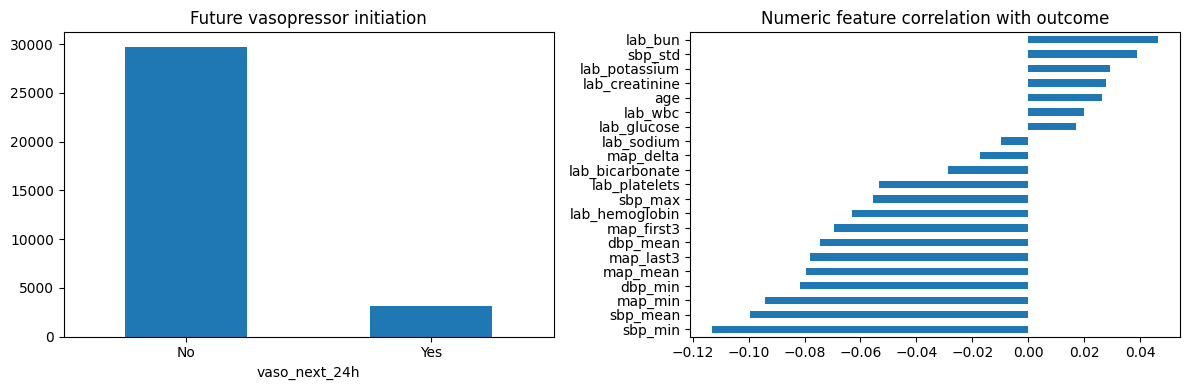

Train: 21041 Validation: 5261 Test: 6576
Class prevalence: {'train': 0.0961, 'validation': 0.0962, 'test': 0.0961}


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TARGET = "vaso_next_24h"
ID_COLUMNS = ["subject_id", "stay_id"]
BP_COLUMNS = [c for c in df.columns if c.startswith(("sbp_", "dbp_", "map_"))]
BASE_COLUMNS = [c for c in df.columns if c not in ID_COLUMNS + [TARGET] + BP_COLUMNS]
BP_LEVEL_COLUMNS = [
    c
    for c in BP_COLUMNS
    if c not in ("sbp_std", "map_delta", "map_first3", "map_last3")
]
BP_TREND_COLUMNS = [c for c in BP_COLUMNS if c not in BP_LEVEL_COLUMNS]
FEATURE_SETS = {
    "Baseline (demographics + labs)": BASE_COLUMNS,
    "BP levels only": BASE_COLUMNS + BP_LEVEL_COLUMNS,
    "Enhanced (+ BP trends)": BASE_COLUMNS + BP_COLUMNS,
}
print("BP level features:", BP_LEVEL_COLUMNS)
print("Additional BP time/variability features:", BP_TREND_COLUMNS)

y = df[TARGET].astype(int)
print("Outcome distribution:", y.value_counts().to_dict())
print("Prevalence:", f"{y.mean():.1%}")
print("Missing fraction (top 20):")
display(
    df[BASE_COLUMNS + BP_COLUMNS].isna().mean().sort_values(ascending=False).head(20)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
y.value_counts().sort_index().plot.bar(
    ax=axes[0], title="Future vasopressor initiation"
)
axes[0].set_xticklabels(["No", "Yes"], rotation=0)
numcols = df[BASE_COLUMNS + BP_COLUMNS].select_dtypes(include="number").columns
corr = (
    df[numcols.tolist() + [TARGET]]
    .corr(numeric_only=True)[TARGET]
    .drop(TARGET)
    .sort_values()
)
corr.plot.barh(ax=axes[1], title="Numeric feature correlation with outcome")
plt.tight_layout()
plt.show()

assert y.nunique() == 2, "Both outcome classes are required"
# Split patients into train (64%), validation (16%) and untouched test (20%).
# The cohort contains only the first stay per subject, so row splits are
# also patient-disjoint. All preprocessing is fitted on training data only.
trainval_idx, test_idx = train_test_split(
    np.arange(len(df)), test_size=0.20, random_state=42, stratify=y
)
train_idx, val_idx = train_test_split(
    trainval_idx, test_size=0.20, random_state=43, stratify=y.iloc[trainval_idx]
)
print("Train:", len(train_idx), "Validation:", len(val_idx), "Test:", len(test_idx))
print(
    "Class prevalence:",
    {
        part: round(float(y.iloc[idx].mean()), 4)
        for part, idx in [
            ("train", train_idx),
            ("validation", val_idx),
            ("test", test_idx),
        ]
    },
)


def make_preprocessor(cols, scale=False):
    categoricals = [c for c in cols if not pd.api.types.is_numeric_dtype(df[c])]
    numerics = [c for c in cols if c not in categoricals]
    num_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if scale:
        num_steps += [("scale", StandardScaler())]
    return ColumnTransformer(
        [
            ("num", Pipeline(num_steps), numerics),
            (
                "cat",
                Pipeline(
                    [
                        ("impute", SimpleImputer(strategy="most_frequent")),
                        (
                            "onehot",
                            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
                        ),
                    ]
                ),
                categoricals,
            ),
        ]
    )


## Additional exploratory analysis: missing measurements

In the executed run, first-six-hour lab measurements are much less complete than BP summaries:

- **Labs:** approximately **37.7–43.5% missing** across the nine selected measurements.
- **BP means/minima:** approximately **3.3–3.4% missing**.
- **MAP change:** approximately **12.2% missing**, because temporal summaries require measurements in the relevant subwindows.

The following plot ranks missingness across input features. Differences in measurement availability may reflect care processes, testing intensity, or documentation and can themselves be predictive. Imputation allows models to train without deleting large numbers of patients, but does **not** recover the unobserved physiological values.

The outcome/feature correlation figure is **descriptive**, not a causal analysis; marginal correlations need not agree with multivariable permutation importance.


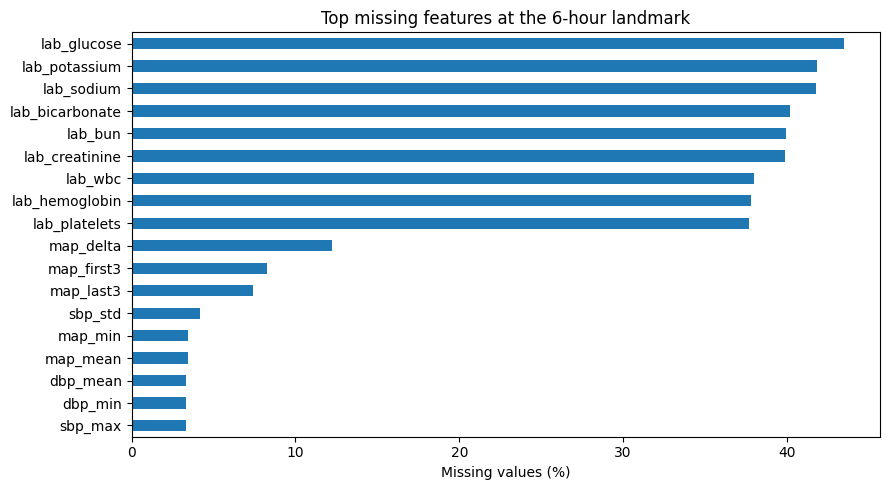

,stays,events,event_rate
first_careunit,,,
Medical Intensive Care Unit (MICU),6226,610,0.097976
Surgical Intensive Care Unit (SICU),5075,349,0.068768
Medical/Surgical Intensive Care Unit (MICU/SICU),5021,329,0.065525
Trauma SICU (TSICU),3925,367,0.093503
Coronary Care Unit (CCU),3820,253,0.06623
Cardiac Vascular Intensive Care Unit (CVICU),3748,1092,0.291355
Neuro Intermediate,3351,53,0.015816
Neuro Surgical Intensive Care Unit (Neuro SICU),865,63,0.072832
Neuro Stepdown,737,16,0.02171


BP measurements available in enhanced model:


,fraction observed
sbp_mean,0.966573
sbp_min,0.966573
sbp_max,0.966573
dbp_mean,0.966543
dbp_min,0.966543
map_mean,0.965813
map_min,0.965813
sbp_std,0.958392
map_last3,0.926182
map_first3,0.917300


In [7]:
missing = df[BASE_COLUMNS + BP_COLUMNS].isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
missing.head(18).sort_values().mul(100).plot.barh(ax=ax)
ax.set_xlabel("Missing values (%)")
ax.set_title("Top missing features at the 6-hour landmark")
plt.tight_layout()
plt.show()

careunit = (
    df.groupby("first_careunit", dropna=False)[TARGET]
    .agg(["count", "sum", "mean"])
    .rename(columns={"count": "stays", "sum": "events", "mean": "event_rate"})
    .sort_values("stays", ascending=False)
)
display(careunit)
print("BP measurements available in enhanced model:")
display(
    df[BP_COLUMNS]
    .notna()
    .mean()
    .sort_values(ascending=False)
    .rename("fraction observed")
)


# 4. Model experiments: algorithms × feature sets

## Models and experimental controls

We compare **Decision Tree, Random Forest, and Gradient Boosting**. Each algorithm is trained separately on all **three** feature sets, producing **nine validation comparisons**. The feature comparisons hold fixed the cohort and train/validation split, so the observed changes are not simply due to different patients.

- **Decision Tree:** a simple, interpretable nonlinear benchmark, but prone to overfitting.
- **Random Forest:** averages many decision trees to reduce variance and capture interactions.
- **Gradient Boosting** (HistGradientBoostingClassifier): a histogram-based ensemble that sequentially builds trees to improve predictive performance.

**Selection metric:** validation AUPRC. We do not use test performance to choose the winning model. Validation AUROC is a supporting metric, not the primary selection criterion.


In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
)

MODELS = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, min_samples_leaf=25, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42,
    ),
    "Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150, l2_regularization=1.0, random_state=42
    ),
}


def get_metrics(y_true, probability, threshold=0.5):
    prediction = (np.asarray(probability) >= threshold).astype(int)
    return {
        "AUROC": roc_auc_score(y_true, probability),
        "AUPRC": average_precision_score(y_true, probability),
        "Precision": precision_score(y_true, prediction, zero_division=0),
        "Recall": recall_score(y_true, prediction, zero_division=0),
        "F1": f1_score(y_true, prediction, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_true, prediction),
    }


trained = {}
records = []
for feature_name, columns in FEATURE_SETS.items():
    for model_name, classifier in MODELS.items():
        pipeline = Pipeline(
            [("prep", make_preprocessor(columns)), ("model", clone(classifier))]
        )
        pipeline.fit(df.iloc[train_idx][columns], y.iloc[train_idx])
        val_probs = pipeline.predict_proba(df.iloc[val_idx][columns])[:, 1]
        key = (feature_name, model_name)
        trained[key] = (pipeline, columns)
        records.append(
            {
                "Feature set": feature_name,
                "Model": model_name,
                **get_metrics(y.iloc[val_idx], val_probs),
            }
        )

validation_results = pd.DataFrame(records).sort_values("AUPRC", ascending=False)
print("MODEL SELECTION: validation-set results only")
display(validation_results.round(3))


MODEL SELECTION: validation-set results only


,Feature set,Model,AUROC,AUPRC,Precision,Recall,F1,Balanced accuracy
8,Enhanced (+ BP trends),Gradient Boosting,0.757,0.347,0.776,0.164,0.271,0.579
7,Enhanced (+ BP trends),Random Forest,0.750,0.339,0.619,0.196,0.297,0.591
4,BP levels only,Random Forest,0.747,0.338,0.588,0.198,0.296,0.591
5,BP levels only,Gradient Boosting,0.756,0.337,0.766,0.162,0.268,0.578
3,BP levels only,Decision Tree,0.740,0.304,0.215,0.583,0.314,0.678
6,Enhanced (+ BP trends),Decision Tree,0.729,0.301,0.165,0.713,0.268,0.665
2,Baseline (demographics + labs),Gradient Boosting,0.719,0.301,0.552,0.115,0.190,0.552
1,Baseline (demographics + labs),Random Forest,0.697,0.287,0.387,0.263,0.313,0.609
0,Baseline (demographics + labs),Decision Tree,0.692,0.265,0.218,0.457,0.295,0.641


# 5. Evaluation and hyperparameter-tuning bonus

The following sequence separates **model selection**, **threshold choice**, **tuning**, and **held-out evaluation**:

1. Compare nine algorithm/feature-set combinations using validation AUPRC.
2. Choose the leading combination from validation performance.
3. Choose an illustrative binary decision threshold using **validation F1**; do not use test outcomes to choose the threshold.
4. Run a separate **Random Forest GridSearchCV** experiment for the assignment's tuning bonus.
5. Apply the fixed trained models to the same held-out test patients and report AUROC, AUPRC, classification diagnostics, and paired uncertainty for the primary BP comparison.

**Why report both AUPRC and precision/recall?** AUPRC summarizes ranking across thresholds; precision and recall describe behavior at a specific threshold, which can be sensitive to the deployment setting and event prevalence.


## Validation model selection and BP ablation

**Executed validation AUPRC** (same patients/splits across all rows):

| Algorithm | A: Baseline | B: + BP levels | C: + BP trends |
|---|---:|---:|---:|
| Decision Tree | 0.2653 | 0.3043 | 0.3013 |
| Random Forest | 0.2872 | 0.3378 | 0.3390 |
| **Gradient Boosting** | **0.3012** | **0.3371** | **0.3466** |

The strongest validation result was **Gradient Boosting + all BP features** (AUPRC **0.3466**). All algorithms improved from A to C, but the additional temporal summaries improved Random Forest and Gradient Boosting only modestly and *slightly worsened* Decision Tree versus BP levels alone.

For Gradient Boosting, adding **BP levels** increased validation AUPRC by about **0.0359** (0.3012 → 0.3371), and adding the **temporal summaries** increased it by a further **~0.0095** (0.3371 → 0.3466). Thus, most of the increase comes from BP levels; trends add a smaller, model-dependent contribution.

The code below recomputes the comparison from executed estimator predictions rather than using the rounded values displayed here.


Best validation model: Gradient Boosting | Enhanced (+ BP trends) | AUPRC = 0.3466

Validation AUPRC comparison:


Feature set,Baseline (demographics + labs),BP levels only,Enhanced (+ BP trends)
Model,,,
Decision Tree,0.2653,0.3043,0.3013
Random Forest,0.2872,0.3378,0.3390
Gradient Boosting,0.3012,0.3371,0.3466


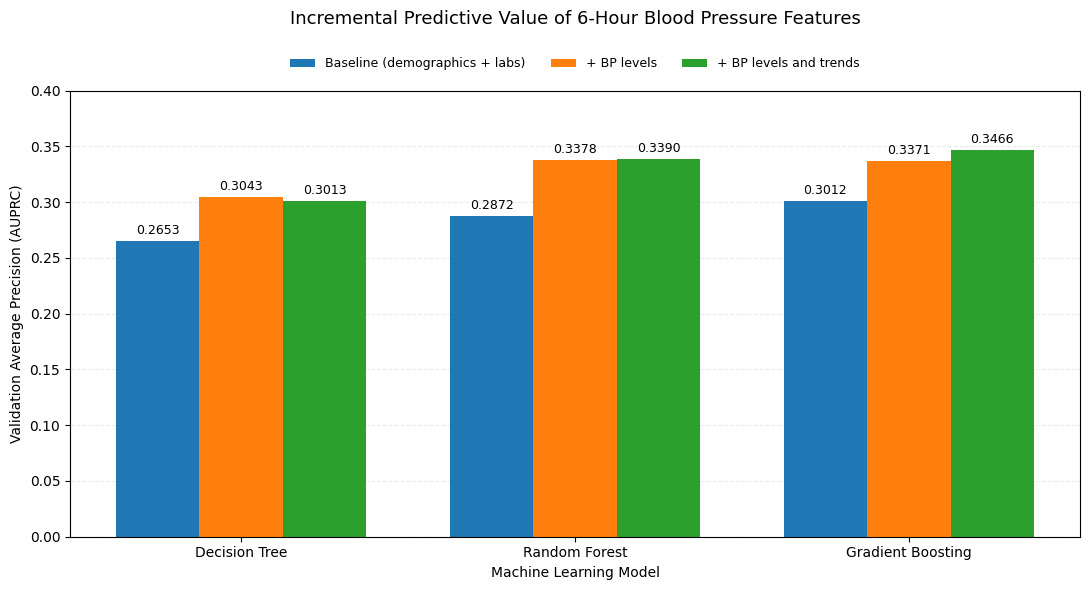


Validation feature-set ablation:


Feature set,Baseline (demographics + labs),BP levels only,Enhanced (+ BP trends),Gain: BP levels,Gain: extra BP summaries
Model,,,,,
Decision Tree,0.2653,0.3043,0.3013,0.0390,-0.0030
Random Forest,0.2872,0.3378,0.3390,0.0506,0.0012
Gradient Boosting,0.3012,0.3371,0.3466,0.0359,0.0094


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Select the best model using validation AUPRC
best_row = validation_results.sort_values("AUPRC", ascending=False).iloc[0]

best_key = (best_row["Feature set"], best_row["Model"])

# Retrieve the already-trained pipeline and feature columns.
best_model, best_cols = trained[best_key]

print(
    f"Best validation model: {best_key[1]} | "
    f"{best_key[0]} | "
    f"AUPRC = {best_row['AUPRC']:.4f}"
)

# 2. Construct three-feature-set comparison
model_order = ["Decision Tree", "Random Forest", "Gradient Boosting"]

feature_order = [
    "Baseline (demographics + labs)",
    "BP levels only",
    "Enhanced (+ BP trends)",
]

comparison = validation_results.pivot(
    index="Model", columns="Feature set", values="AUPRC"
).reindex(index=model_order, columns=feature_order)

assert (
    not comparison.isna().any().any()
), "Missing validation results for one or more combinations."

print("\nValidation AUPRC comparison:")
display(comparison.round(4))

# 3. Plot all nine model/feature-set combinations
x = np.arange(len(model_order))
width = 0.25

fig, ax = plt.subplots(figsize=(11, 6))

legend_labels = [
    "Baseline (demographics + labs)",
    "+ BP levels",
    "+ BP levels and trends",
]

for i, (feature_set, label) in enumerate(zip(feature_order, legend_labels)):
    bars = ax.bar(
        x + (i - 1) * width, comparison[feature_set].values, width, label=label
    )

    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(model_order)

ax.set_xlabel("Machine Learning Model")
ax.set_ylabel("Validation Average Precision (AUPRC)")

ax.set_title(
    "Incremental Predictive Value of 6-Hour Blood Pressure Features",
    fontsize=13,
    pad=48,
)

ax.set_ylim(0, max(0.40, comparison.to_numpy().max() * 1.15))

# Legend above the plot to avoid covering the bars.
ax.legend(
    loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=False, fontsize=9
)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


# 4. Feature-set ablation analysis
ablation = comparison.copy()

ablation["Gain: BP levels"] = (
    ablation["BP levels only"] - ablation["Baseline (demographics + labs)"]
)

ablation["Gain: extra BP summaries"] = (
    ablation["Enhanced (+ BP trends)"] - ablation["BP levels only"]
)

print("\nValidation feature-set ablation:")
display(ablation.round(4))


## Validation-based threshold selection

AUPRC and AUROC measure ranking without a fixed probability threshold. To illustrate a binary clinical-risk flag, the next cell selects a threshold using **validation F1**, balancing precision and recall mathematically (rather than setting a clinically approved utility function).

In the executed run, the selected threshold was **0.151**, below the conventional 0.5 default. This favors identifying more future initiations but increases false alerts. The resulting classification rule is **not** validated for clinical use; determining an acceptable operating point would require prospective validation and explicit consideration of the harms of missed events and unnecessary alerts.


In [10]:
from sklearn.metrics import precision_recall_curve

val_probs = best_model.predict_proba(df.iloc[val_idx][best_cols])[:, 1]
precision_curve, recall_curve, thresholds = precision_recall_curve(
    y.iloc[val_idx], val_probs
)
f1_curve = (
    2
    * precision_curve[:-1]
    * recall_curve[:-1]
    / np.maximum(precision_curve[:-1] + recall_curve[:-1], 1e-12)
)
selected_threshold = float(thresholds[np.argmax(f1_curve)])
print("Validation-selected F1 threshold:", round(selected_threshold, 3))
print("Validation F1 at 0.5:", round(get_metrics(y.iloc[val_idx], val_probs)["F1"], 3))
print(
    "Validation F1 at selected threshold:",
    round(get_metrics(y.iloc[val_idx], val_probs, selected_threshold)["F1"], 3),
)


Validation-selected F1 threshold: 0.151
Validation F1 at 0.5: 0.271
Validation F1 at selected threshold: 0.354


## Bonus experiment: hyperparameter tuning

We optimize an enhanced-feature **Random Forest** using `GridSearchCV` **only within the training cohort**, with **3-fold stratified cross-validation** and AUPRC (`average_precision`) as the selection score. The search explores **eight** combinations of tree count, maximum depth, and minimum leaf size.

In the executed run, the best search configuration was **200 trees, unrestricted maximum depth, and minimum 10 samples per leaf**. Best mean training-CV AUPRC was **0.371**, and tuned Random Forest validation AUPRC was **0.341**.

The tuning exercise fulfills the assignment's bonus-style methodological comparison; tuning does **not** have to outperform every other model to be informative.


In [11]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

bonus_cols = FEATURE_SETS["Enhanced (+ BP trends)"]
rf_pipe = Pipeline(
    [
        ("prep", make_preprocessor(bonus_cols)),
        (
            "model",
            RandomForestClassifier(
                random_state=42, n_jobs=-1, class_weight="balanced_subsample"
            ),
        ),
    ]
)
search = GridSearchCV(
    estimator=rf_pipe,
    param_grid={
        "model__n_estimators": [100, 200],
        "model__max_depth": [8, None],
        "model__min_samples_leaf": [3, 10],
    },
    scoring="average_precision",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=2,
    verbose=1,
    refit=True,
)
search.fit(df.iloc[train_idx][bonus_cols], y.iloc[train_idx])
print("Best training-CV AUPRC:", round(search.best_score_, 3))
print("Best parameters:", search.best_params_)
tuned_val_prob = search.predict_proba(df.iloc[val_idx][bonus_cols])[:, 1]
print(
    "Tuned RF validation:",
    {k: round(v, 3) for k, v in get_metrics(y.iloc[val_idx], tuned_val_prob).items()},
)
print(
    "Untuned enhanced RF validation AUPRC:",
    round(
        float(
            validation_results.query(
                'Model == "Random Forest" and `Feature set` == "Enhanced (+ BP trends)"'
            )["AUPRC"].iloc[0]
        ),
        3,
    ),
)


Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best training-CV AUPRC: 0.371
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 10, 'model__n_estimators': 200}
Tuned RF validation: {'AUROC': np.float64(0.749), 'AUPRC': np.float64(0.341), 'Precision': 0.455, 'Recall': 0.241, 'F1': 0.315, 'Balanced accuracy': np.float64(0.605)}
Untuned enhanced RF validation AUPRC: 0.339


## Final held-out evaluation

**Model selection and threshold selection occurred before test-set evaluation.** The code below reports final metrics for the selected full-feature Gradient Boosting model, the tuned Random Forest bonus comparator, and a **matched feature-set comparison** using Gradient Boosting on exactly the same **6,576 test patients**.

### Held-out test results: Gradient Boosting (executed run)

| Feature set | Test AUROC | Test AUPRC |
|---|---:|---:|
| A: Demographics + labs | 0.7245 | 0.3182 |
| B: A + BP levels | 0.7665 | 0.3883 |
| C: B + BP temporal summaries | **0.7692** | **0.3996** |

**Primary result:** The full-feature model improved AUPRC by **+0.0814** over baseline (**+25.6% relative**). The paired, class-stratified bootstrap produced a **95% percentile interval of +0.0553 to +0.1034**, supporting a positive difference within this selected held-out sample; it does not address external transportability or selection bias.

### Threshold-dependent diagnostics

At the validation-chosen threshold **0.151**, enhanced Gradient Boosting achieved approximately **precision 0.333, recall 0.419, and F1 0.371**. In the displayed confusion matrix, **265** positive cases were identified and **367** were missed; **531** negatives were flagged as positives. AUPRC **0.400** is around four times the **9.61%** cohort event prevalence, but predictive accuracy is not sufficient for an autonomous clinical decision rule.

The tuned RF achieved test AUPRC **0.394** and AUROC **0.768**, close to but below enhanced Gradient Boosting; its displayed F1 uses the **0.5** threshold rather than the selected Gradient Boosting threshold, so those F1 values are **not a threshold-matched head-to-head comparison**.


Selected model: ('Enhanced (+ BP trends)', 'Gradient Boosting')
Threshold: 0.151
TEST METRICS:


,AUROC,AUPRC,Precision,Recall,F1,Balanced accuracy
0,0.769,0.4,0.333,0.419,0.371,0.665


              precision    recall  f1-score   support

           0       0.94      0.91      0.92      5944
           1       0.33      0.42      0.37       632

    accuracy                           0.86      6576
   macro avg       0.63      0.66      0.65      6576
weighted avg       0.88      0.86      0.87      6576



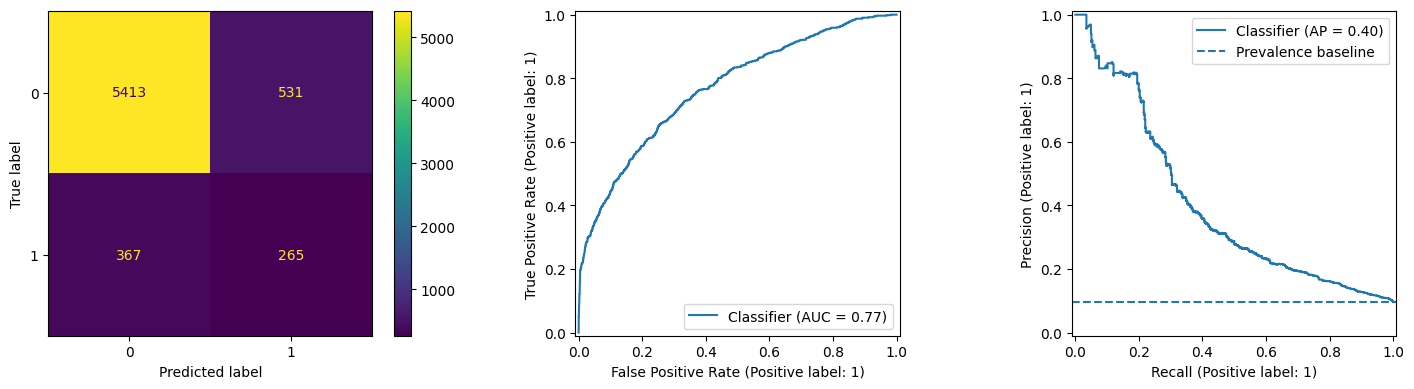

BONUS tuned RF test metrics (0.5 threshold):


,AUROC,AUPRC,Precision,Recall,F1,Balanced accuracy
0,0.768,0.394,0.52,0.286,0.369,0.629


MATCHED HELD-OUT TEST — Gradient Boosting (threshold=0.5 for threshold metrics)


,AUROC,AUPRC,Precision,Recall,F1,Balanced accuracy
Feature set,,,,,,
Baseline (demographics + labs),0.7245,0.3182,0.6187,0.1361,0.2231,0.5636
BP levels only,0.7665,0.3883,0.8163,0.1899,0.3081,0.5927
Enhanced (+ BP trends),0.7692,0.3996,0.8121,0.1915,0.3099,0.5934


Test AUPRC full-minus-baseline: +0.0814
Paired stratified bootstrap 95% percentile interval for AUPRC improvement: [0.0553 0.1034]


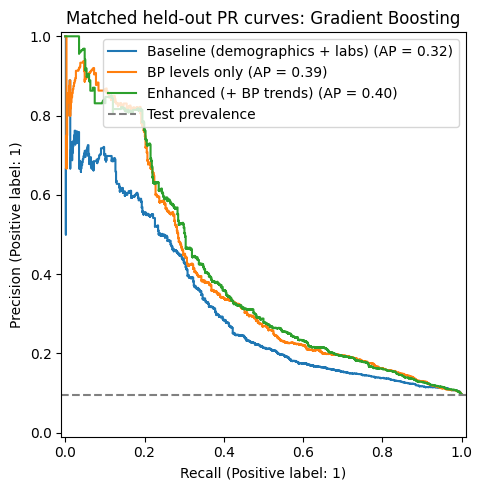

In [12]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
    classification_report,
)

test_probs = best_model.predict_proba(df.iloc[test_idx][best_cols])[:, 1]
test_pred = (test_probs >= selected_threshold).astype(int)
print("Selected model:", best_key)
print("Threshold:", round(selected_threshold, 3))
print("TEST METRICS:")
display(
    pd.DataFrame([get_metrics(y.iloc[test_idx], test_probs, selected_threshold)]).round(
        3
    )
)
print(classification_report(y.iloc[test_idx], test_pred, zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_predictions(y.iloc[test_idx], test_pred, ax=axes[0])
RocCurveDisplay.from_predictions(y.iloc[test_idx], test_probs, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y.iloc[test_idx], test_probs, ax=axes[2])
axes[2].axhline(y.iloc[test_idx].mean(), linestyle="--", label="Prevalence baseline")
axes[2].legend()
plt.tight_layout()
plt.show()

bonus_test_probs = search.predict_proba(df.iloc[test_idx][bonus_cols])[:, 1]
print("BONUS tuned RF test metrics (0.5 threshold):")
display(pd.DataFrame([get_metrics(y.iloc[test_idx], bonus_test_probs)]).round(3))

# Matched held-out comparison — NO model selection on the test set.
fixed_model_name = "Gradient Boosting"
heldout_rows = []
heldout_probs = {}
for feature_name in FEATURE_SETS:
    pipe, cols = trained[(feature_name, fixed_model_name)]
    probs = pipe.predict_proba(df.iloc[test_idx][cols])[:, 1]
    heldout_probs[feature_name] = probs
    heldout_rows.append(
        {
            "Feature set": feature_name,
            **get_metrics(y.iloc[test_idx], probs, threshold=0.5),
        }
    )
heldout_comparison = pd.DataFrame(heldout_rows).set_index("Feature set")
print("MATCHED HELD-OUT TEST — Gradient Boosting (threshold=0.5 for threshold metrics)")
display(heldout_comparison.round(4))
base_name = "Baseline (demographics + labs)"
full_name = "Enhanced (+ BP trends)"
observed_difference = (
    heldout_comparison.loc[full_name, "AUPRC"]
    - heldout_comparison.loc[base_name, "AUPRC"]
)
print(f"Test AUPRC full-minus-baseline: {observed_difference:+.4f}")

# Same test patients in every replicate; sample *within class* to avoid
# bootstrap resamples with zero positives.
rng = np.random.default_rng(2026)
y_test_array = y.iloc[test_idx].to_numpy()
pos = np.flatnonzero(y_test_array == 1)
neg = np.flatnonzero(y_test_array == 0)
paired_deltas = []
for _ in range(500):
    sample = np.concatenate(
        [
            rng.choice(pos, len(pos), replace=True),
            rng.choice(neg, len(neg), replace=True),
        ]
    )
    ap_full = average_precision_score(
        y_test_array[sample], heldout_probs[full_name][sample]
    )
    ap_base = average_precision_score(
        y_test_array[sample], heldout_probs[base_name][sample]
    )
    paired_deltas.append(ap_full - ap_base)
print(
    "Paired stratified bootstrap 95% percentile interval for AUPRC improvement:",
    np.round(np.percentile(paired_deltas, [2.5, 97.5]), 4),
)

fig, ax = plt.subplots(figsize=(7, 5))
for feature_name in FEATURE_SETS:
    PrecisionRecallDisplay.from_predictions(
        y.iloc[test_idx], heldout_probs[feature_name], name=feature_name, ax=ax
    )
ax.axhline(
    float(y.iloc[test_idx].mean()),
    linestyle="--",
    color="grey",
    label="Test prevalence",
)
ax.legend()
ax.set_title("Matched held-out PR curves: Gradient Boosting")
plt.tight_layout()
plt.show()


## Model interpretation: permutation feature importance

The next cell estimates importance by permuting one input column at a time on the **validation data** and measuring the decrease in AUPRC. The executed results rank **first care unit** (about **0.109** AUPRC drop) and **mean systolic BP** (about **0.066**) highest, followed by minimum systolic BP (\~0.013), MAP change (\~0.012), and late-window MAP (\~0.011).

**Interpretation:** The strong care-unit effect plausibly reflects case-mix and clinical-treatment practice variation. BP measures supply predictive information related to early hemodynamic status; the smaller contributions of MAP change and late MAP are consistent with the incremental value observed in the feature-set ablation. Permutation importance can be unstable when variables are correlated; none of these associations demonstrates causality.


,Validation AUPRC drop on permutation
first_careunit,0.108726
sbp_mean,0.065975
sbp_min,0.013078
map_delta,0.011817
map_last3,0.010725
age,0.005344
lab_wbc,0.002978
dbp_min,0.002407
lab_glucose,0.001698
admission_type,0.000937


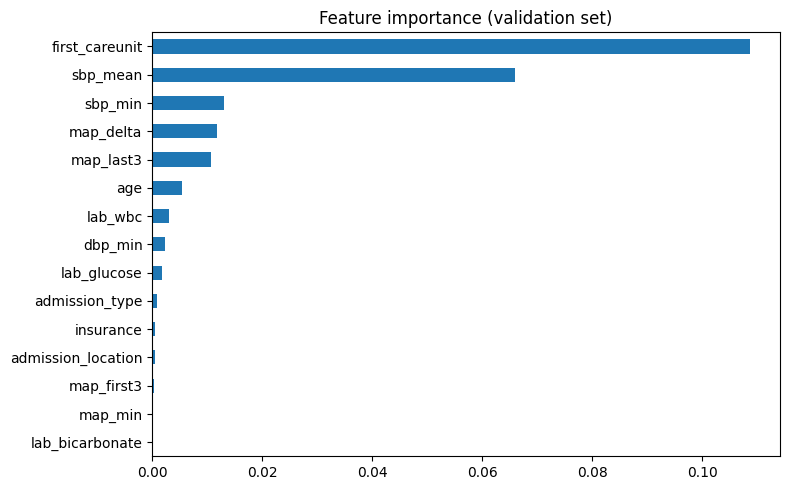

INTERPRETATION GUIDANCE:
1. Compare validation AUPRC for matched algorithms, with vs without BP features.
2. Relate test AUPRC to the event prevalence, not only to AUROC.
3. Examine recall and precision at the validation-selected threshold.
4. Avoid interpreting associations as causal effects or medical recommendations.

LIMITATIONS: Complete 30-hour ICU observation selects longer-staying patients;
vasopressor receipt reflects clinical treatment decisions, not shock diagnosis;
charting frequency/missingness, treatment documentation and single-center data
may limit transportability. Excluding early infusions can shift the target population.

ADDITIONAL STUDY CAVEATS:
- First care unit includes all unit labels present in MIMIC-IV icustays;
  intermediate and stepdown labels were not automatically excluded.
- The 30-hour stay criterion is future information used in cohort selection,
  creating selection bias and limiting six-hour deployment claims.
- BP-derived features show associations,

In [13]:
from sklearn.inspection import permutation_importance

# Permutation importance on validation data keeps the final test set sealed
# for additional diagnostics and exploratory decisions.
importance_result = permutation_importance(
    best_model,
    df.iloc[val_idx][best_cols],
    y.iloc[val_idx],
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=2,
)
importance = pd.Series(importance_result.importances_mean, index=best_cols).sort_values(
    ascending=False
)
display(importance.head(15).rename("Validation AUPRC drop on permutation"))
importance.head(15).sort_values().plot.barh(
    figsize=(8, 5), title="Feature importance (validation set)"
)
plt.tight_layout()
plt.show()

print("INTERPRETATION GUIDANCE:")
print(
    "1. Compare validation AUPRC for matched algorithms, with vs without BP features."
)
print("2. Relate test AUPRC to the event prevalence, not only to AUROC.")
print("3. Examine recall and precision at the validation-selected threshold.")
print(
    "4. Avoid interpreting associations as causal effects or medical recommendations."
)
print(
    "\nLIMITATIONS: Complete 30-hour ICU observation selects longer-staying patients;"
)
print("vasopressor receipt reflects clinical treatment decisions, not shock diagnosis;")
print("charting frequency/missingness, treatment documentation and single-center data")
print(
    "may limit transportability. Excluding early infusions can shift the target population."
)

print("\nADDITIONAL STUDY CAVEATS:")
print("- First care unit includes all unit labels present in MIMIC-IV icustays;")
print("  intermediate and stepdown labels were not automatically excluded.")
print("- The 30-hour stay criterion is future information used in cohort selection,")
print("  creating selection bias and limiting six-hour deployment claims.")
print("- BP-derived features show associations, not causal benefits of monitoring.")
print("- Incomplete/fragmented administration records can mislabel therapy starts.")


# 6. Discussion, limitations, and key takeaways

## Answer to the research question

**Yes, early BP information improved prediction of later recorded vasopressor initiation in this retrospective, selected MIMIC-IV cohort.** Full-feature Gradient Boosting increased held-out AUPRC from **0.3182** to **0.3996**, an **absolute gain of 0.0814** (**25.6% relative**). The paired bootstrap 95% interval was **[+0.0553, +0.1034]**. The largest increment arose from BP *levels*; within-window temporal summaries offered a smaller additional gain.

## Key limitations

1. **Complete 30-hour observation / selection bias:** Requiring ICU observation through hour 30 uses future ICU duration to define eligibility and excludes patients who leave or die earlier. Results should not be generalized to every patient eligible at hour six.
2. **Treatment-based outcome:** An `inputevents` initiation reflects documented treatment and clinician decisions, not objectively verified shock or a need for vasopressors. Fragmented infusion rows, charting conventions, and medication variants may misclassify timing.
3. **Unit heterogeneity:** First ICU unit is the strongest predictor and may capture differences in case mix, operations, and institutional practices. Stepdown/intermediate designations were retained where present in `icustays`.
4. **Data completeness:** Labs had approximately 37.7–43.5% missingness in the observation window. Imputation handles computation, but informative missingness and uneven measurement frequency may bias associations.
5. **Clinical utility and transportability:** Precision **0.333** and recall **0.419** at the chosen illustrative threshold leave many false alerts and missed cases. Single-center retrospective results lack external and prospective validation, calibration assessment, and formal decision-utility analysis.

## Takeaway

The experiment illustrates how to define a time-bounded EHR prediction problem, avoid using measurements after the landmark, compare controlled feature sets, select models without test-set peeking, evaluate an imbalanced outcome, and interpret the limits of a predictive association. **It is a tutorial of ML methods, not a clinically deployable risk score or a recommendation to initiate therapy.**
